# Micrograd study



In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

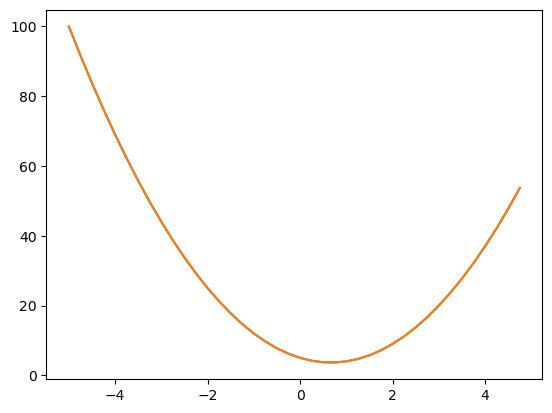

In [8]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs, ys)
plt.show()

In [9]:
h = 0.00001
x = 2/3
(f(x + h) - f(x)) / h

3.0000002482211127e-05

In [11]:
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [14]:
h = 0.001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c

print('d1', d1)
print('d2', d2)
print('slope', (d2 - d1) / h)

d1 4.0
d2 3.997
slope -3.0000000000001137


In [191]:
import math


class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad = 1.0 * out.grad
            other.grad = 1.0 * out.grad
        
        out._backward = _backward
        return out

    def __mul__(self, other):
        out  = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad
        out._backward = _backward
        
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

Value(data=-8.0)

In [53]:
d._op
%pip install graphviz


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [54]:
d

Value(data=4.0)

In [118]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges
        

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(
            name = uid,
            label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),
            shape = 'record'
        )
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

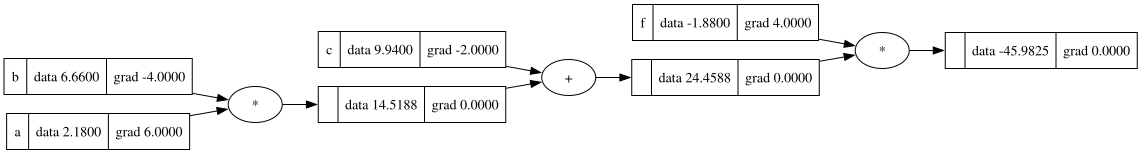

In [129]:
draw_dot(L)

In [123]:
c.grad = -2.0
e.grad = -2.0

dd / dc = 1.0
dd / de = 1.0

dL / dc = (dL /dd) * (dd / dc)
d = c + e

In [124]:
f.grad = 4.0
d.grad = -2.0

In [125]:
L.grad = 1.0

In [126]:
a.grad = -2.0 * -3.0
b.grad = -2.0 * 2.0

dl / de = -2.0
e = a * b
de / da = b
dL / da = (dl / de) * (de / da)

In [127]:
# on leaf nodes
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f
print(L.data)

-45.982544000000004


In [128]:
def lol():
    h = 0.0001
    
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L' 
    L1 = L.data

    a = Value(2.0 , label='a')
    a.data += h
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L' 
    L2 = L.data 

    print((L2 - L1) / h)

In [110]:
lol()

6.000000000021544


In [113]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

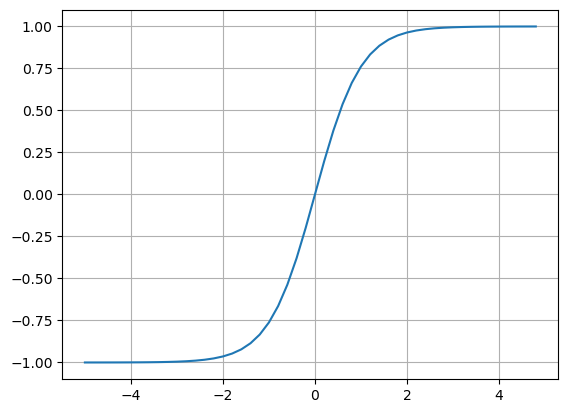

In [114]:
plt.show()

In [192]:
#inputs
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias
b = Value(6.8813735870195432, label="b")

x1w1 = x1*w1; x1w1.label = "x1*w1"
x2w2 = x2*w2; x2w2.label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'


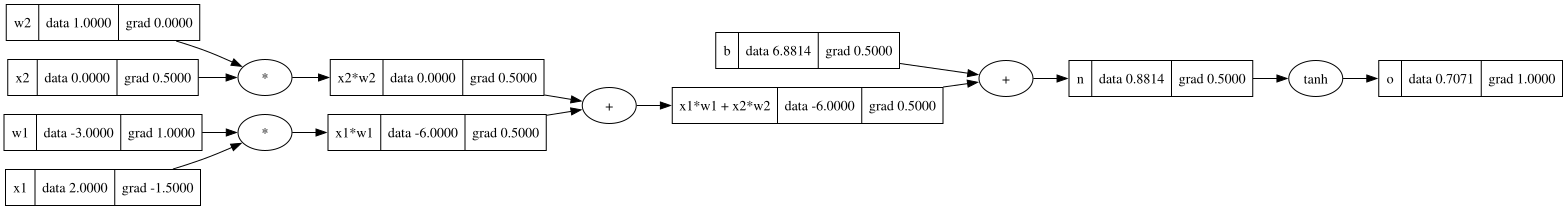

In [195]:
draw_dot(o)

In [194]:
o.backward()

In [186]:
# topological sort for dependencies
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.881373587019543),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [172]:
o.grad = 1.0

In [173]:
o._backward()

In [174]:
n._backward()

In [176]:
b._backward()

In [177]:
x1w1x2w2._backward()

In [179]:
x2w2._backward()

In [181]:
x1w1._backward()

In [149]:
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

In [147]:
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

In [144]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [142]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [140]:
n.grad = 0.5

In [137]:
o.grad = 1.0

In [139]:
1 - o.data**2

0.4999999999999999

In [ ]:
# o = tanh(n)
# do/dn = 1 - tanh(n) ** 2